### Model Error Analysis
Plot model output with respect to different parameters.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

### Initial data processing

In [2]:
# Load the CSV data
df = pd.read_csv('../combined_results.csv')
df.head()

,site,latitude,longitude,output_years,bias_s00000000_ghec,rmse_s00000000_ghec,model_snow_days_s00000000_ghec,snotel_snow_days,mean_snotel_swe,var_snotel_swe,bias_s01011010_gbc,rmse_s01011010_gbc,model_snow_days_s01011010_gbc,bias_s01011010_ghec,rmse_s01011010_ghec,model_snow_days_s01011010_ghec,bias_s01011010_ghelaps,rmse_s01011010_ghelaps,model_snow_days_s01011010_ghelaps
0,Forestdale Creek,38.68,-119.96,16.0,-95.3,168.5,2909,3065,277.6,150622.6,7.2,63.5,3053,131.3,251.7,3678,55.8,106.6,3152
1,Horse Meadow,38.84,-119.89,11.2,-22.0,66.2,1627,1704,127.6,38347.5,-8.3,49.7,1601,49.2,110.3,1984,19.7,64.6,1723
2,Burnside Lake,38.72,-119.89,16.0,-7.2,89.5,3124,3055,196.3,83372.0,34.3,75.5,3081,133.7,254.1,3760,78.0,150.9,3269
3,Summit Meadow,38.40,-119.54,9.2,-9.4,67.5,1186,1153,103.5,25719.7,5.7,31.2,1176,67.9,140.2,1468,38.3,84.2,1312
4,Carson Pass,38.69,-120.00,14.0,-67.7,124.9,2500,2705,233.7,107471.6,-12.9,56.2,2585,87.3,205.2,3138,28.2,84.4,2719


In [3]:
# Remove sites where 'output_years' < 5
df = df[df['output_years'] >= 5]

In [4]:
# Create a dataframe for bias
bias_df = df[['site', 'latitude', 'longitude', 'mean_snotel_swe', 'var_snotel_swe', 'bias_s00000000_ghec', 'bias_s01011010_ghec', 'bias_s01011010_ghelaps', 'bias_s01011010_gbc']].copy()

In [5]:
bias_df['nbias_s00000000_ghec'] = bias_df['bias_s00000000_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghec'] = bias_df['bias_s01011010_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghelaps'] = bias_df['bias_s01011010_ghelaps'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_gbc'] = bias_df['bias_s01011010_gbc'] / bias_df['mean_snotel_swe']

In [9]:
# Load topography data
SNOTEL_PATH = '/home/chriscox/Data/snotel/'
snotel_topo = pd.read_csv(SNOTEL_PATH + 'snotel_land_data.csv')
snotel_topo

,SNOTEL Name,SNOTEL Lat (),SNOTEL Lon (),points_x,ELEVATION,points_y,SLOPE,points_x.1,ASPECT,points_y.1,SKY_VIEW_FACTOR,points,TERRAIN_CONFIG
0,Annie Springs,42.87,-122.17,0,1917.0,0,4.0,0,187.0,0,1.00,0,0.00
1,Long Lake,58.19,-133.83,1,414.0,1,11.0,1,147.0,1,0.93,1,0.06
2,Mcneil Canyon,59.74,-151.25,2,327.0,2,6.0,2,165.0,2,0.99,2,0.00
3,Ute Creek,37.61,-105.37,3,3249.0,3,11.0,3,131.0,3,0.99,3,0.00
4,Lewis Peak,40.36,-116.86,4,2277.0,4,6.0,4,234.0,4,0.99,4,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
824,Moscow Mountain,46.81,-116.85,824,1279.0,824,6.0,824,72.0,824,1.00,824,-0.00
825,Beaver Pass,48.88,-121.26,825,1259.0,825,15.0,825,103.0,825,0.94,825,0.04
826,Bear River RS,40.89,-110.83,826,2615.0,826,3.0,826,276.0,826,1.00,826,0.00
827,Easy Pass,48.86,-121.44,827,1439.0,827,18.0,827,215.0,827,0.94,827,0.03


In [16]:
# Merge bias_df with snotel_topo on site name
# Need to match 'site' in bias_df with 'SNOTEL Name' in snotel_topo
merged_df = bias_df.merge(snotel_topo[['SNOTEL Name', 'ELEVATION', 'SLOPE', 'SKY_VIEW_FACTOR', 'ASPECT']], 
                          left_on='site', right_on='SNOTEL Name', how='inner')

# Transform aspect into northness and eastness components
# Northness: cos(aspect) ranges from -1 (south) to +1 (north)
# Eastness: sin(aspect) ranges from -1 (west) to +1 (east)
merged_df['northness'] = np.cos(np.radians(merged_df['ASPECT']))
merged_df['eastness'] = np.sin(np.radians(merged_df['ASPECT']))

### Map Plot
Change as needed

In [20]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

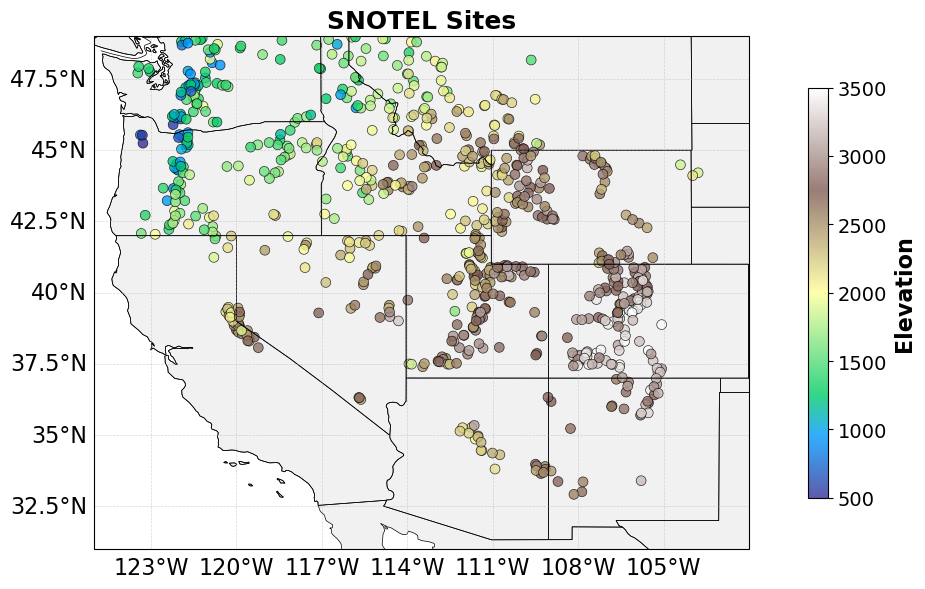

In [23]:
# Single map plot
map_type = 'Elevation'
map_configs = {'Elevation':'ELEVATION'}
fig = plt.figure(figsize=(12, 6))
ax = plt.subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
scatter = ax.scatter(merged_df['longitude'], merged_df['latitude'],
                     c=merged_df[map_configs[map_type]],
                     s=50,
                     alpha=0.8,
                     cmap='terrain',
                     vmin=500,
                     vmax=3500,
                     transform=ccrs.PlateCarree(),
                     edgecolors='black',
                     linewidth=0.5)
cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
cbar.set_label(map_type, fontsize=16, fontweight='bold')
cbar.ax.tick_params(labelsize=14)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
ax.set_title('SNOTEL Sites', fontsize=18, fontweight='bold')
plt.tight_layout()

### Plot data

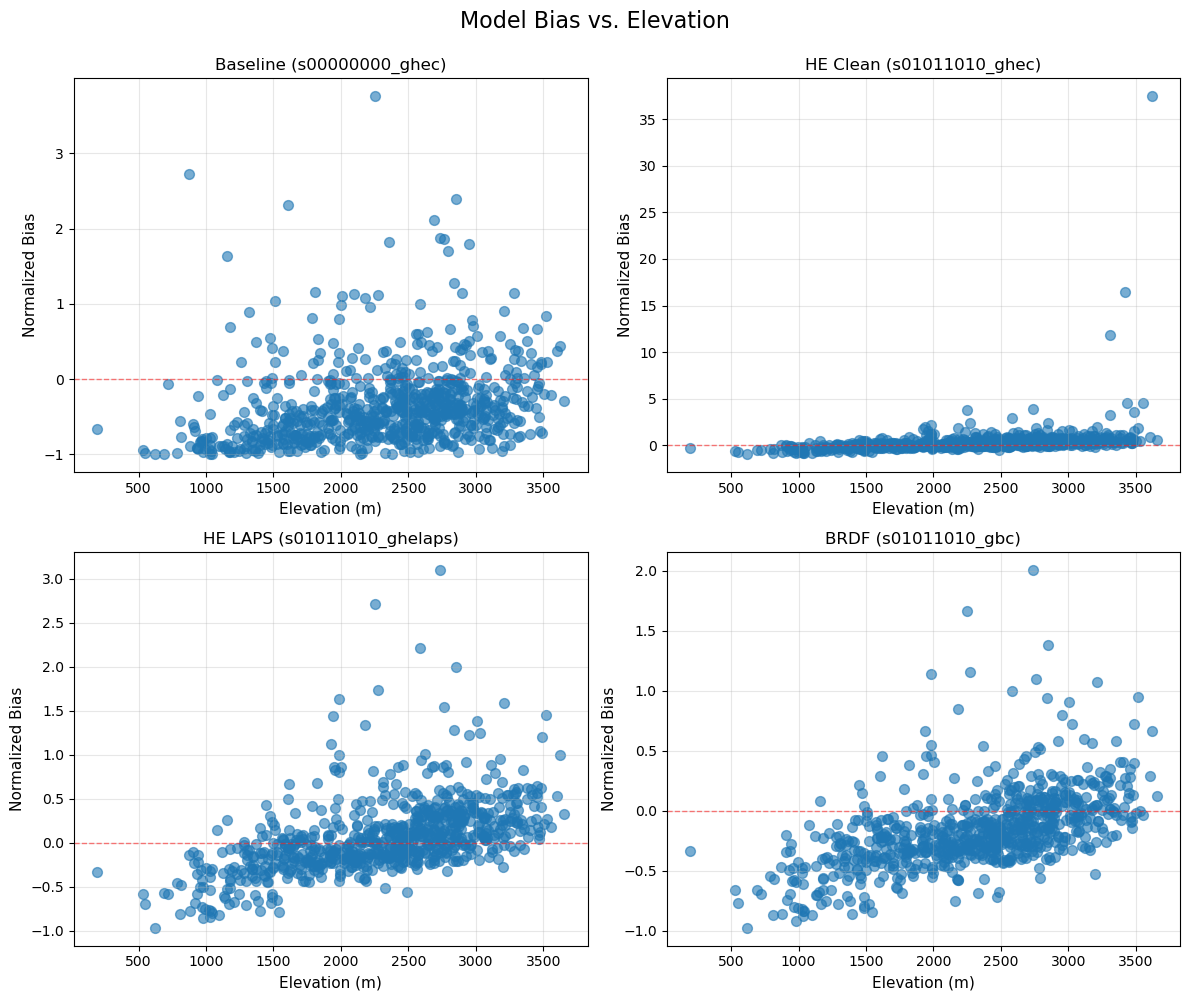

Number of sites plotted: 765


In [13]:
# Create 2x2 subplot figure
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Elevation', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['ELEVATION'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Elevation (m)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Number of sites plotted: {len(merged_df)}")

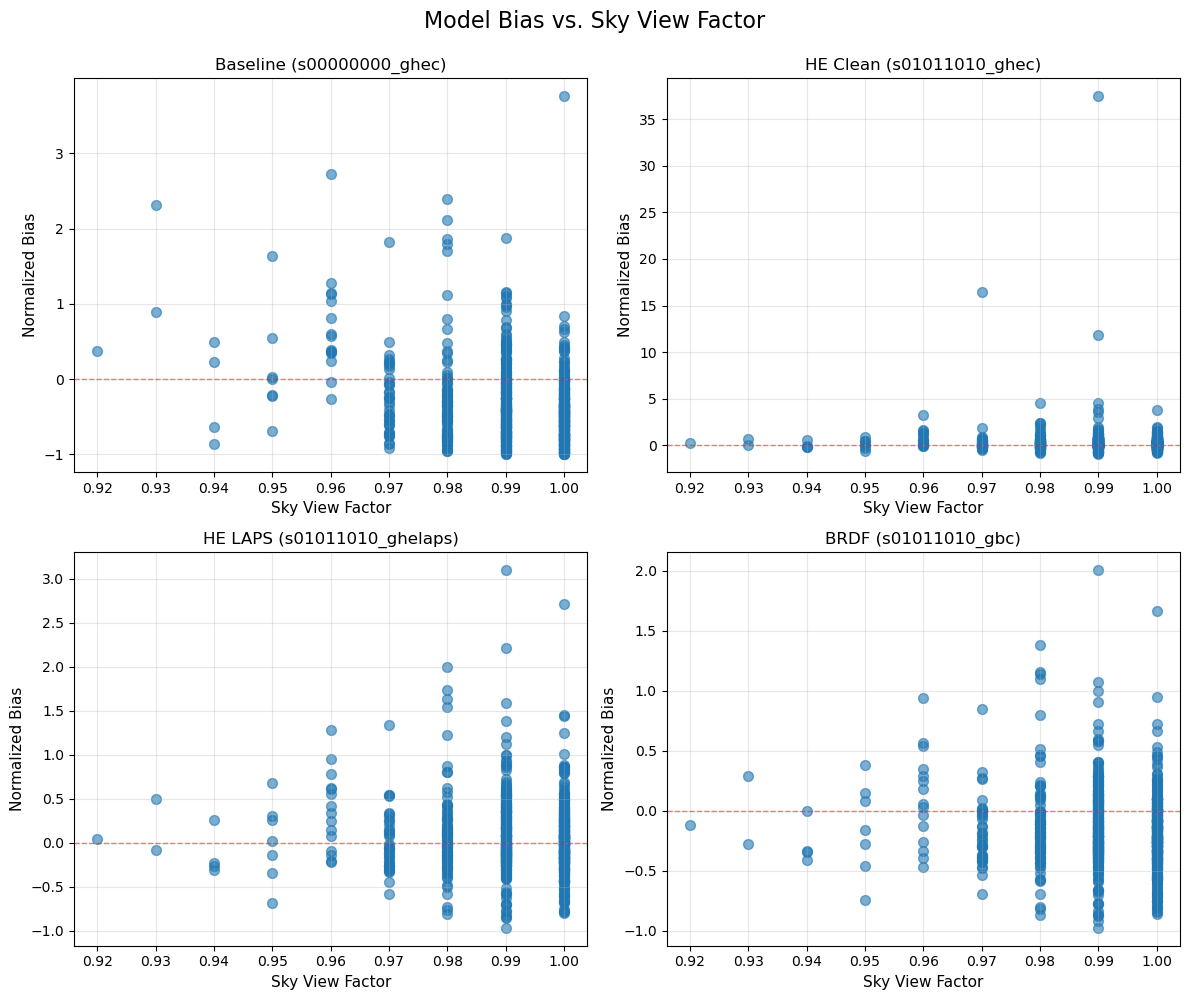

In [14]:
# Create 2x2 subplot figure for SKY_VIEW_FACTOR
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Sky View Factor', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['SKY_VIEW_FACTOR'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Sky View Factor', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

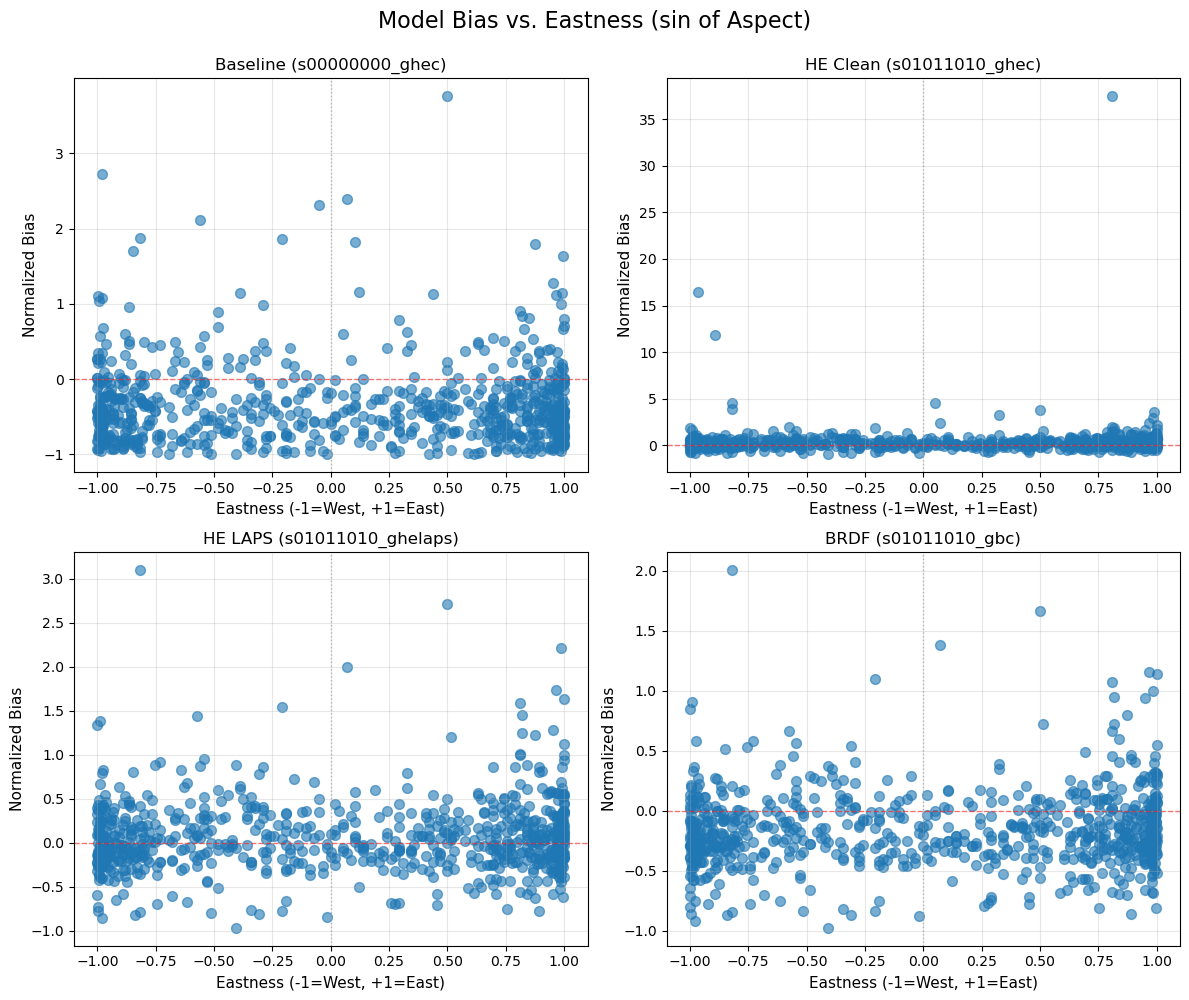

In [17]:
# Create 2x2 subplot figure for Eastness (sin of aspect)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Eastness (sin of Aspect)', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['eastness'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Eastness (-1=West, +1=East)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)
    # Add a vertical line at x=0 to separate east/west facing
    ax.axvline(x=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

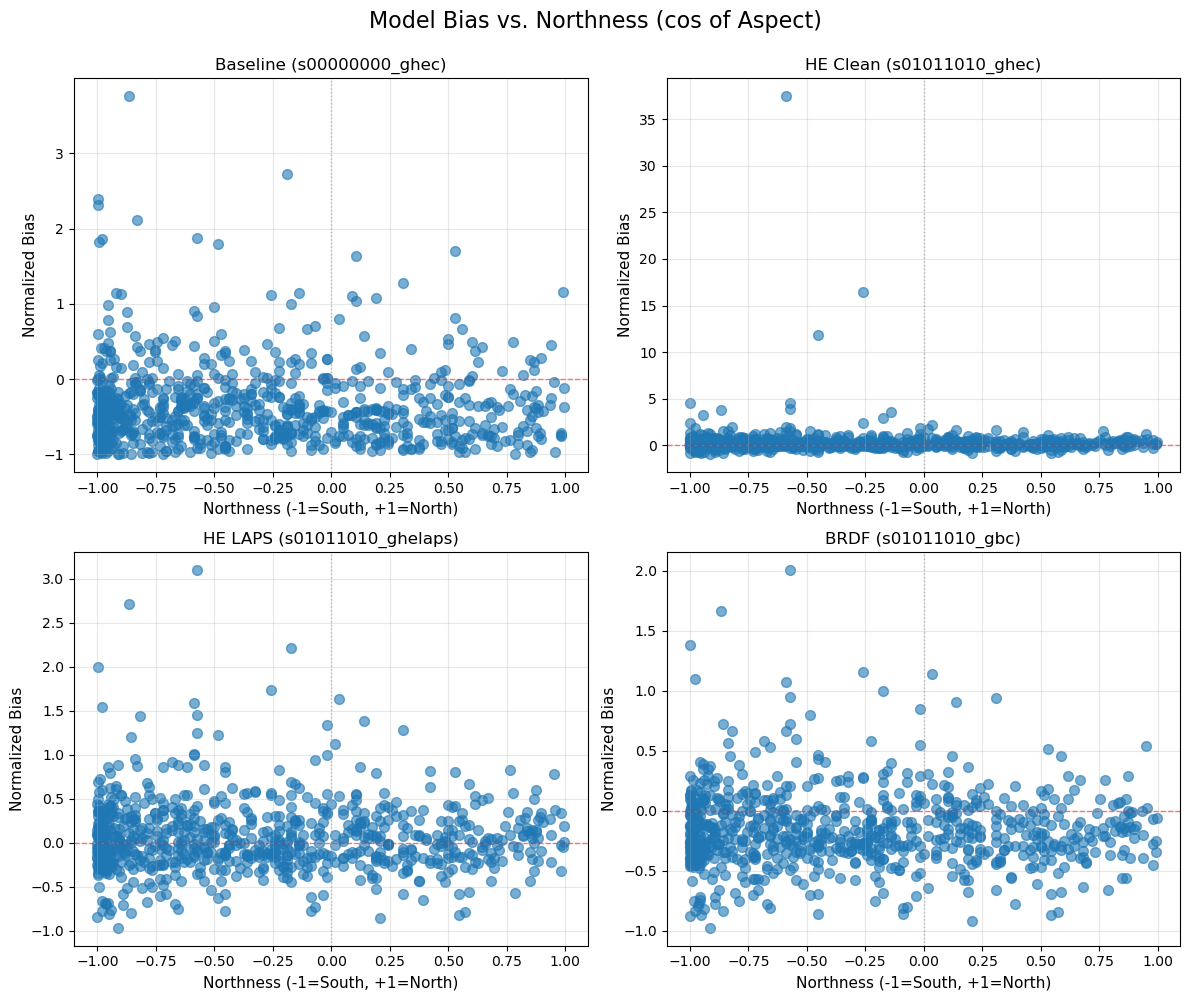

In [18]:
# Create 2x2 subplot figure for Northness (cos of aspect)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Northness (cos of Aspect)', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['northness'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Northness (-1=South, +1=North)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)
    # Add a vertical line at x=0 to separate north/south facing
    ax.axvline(x=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

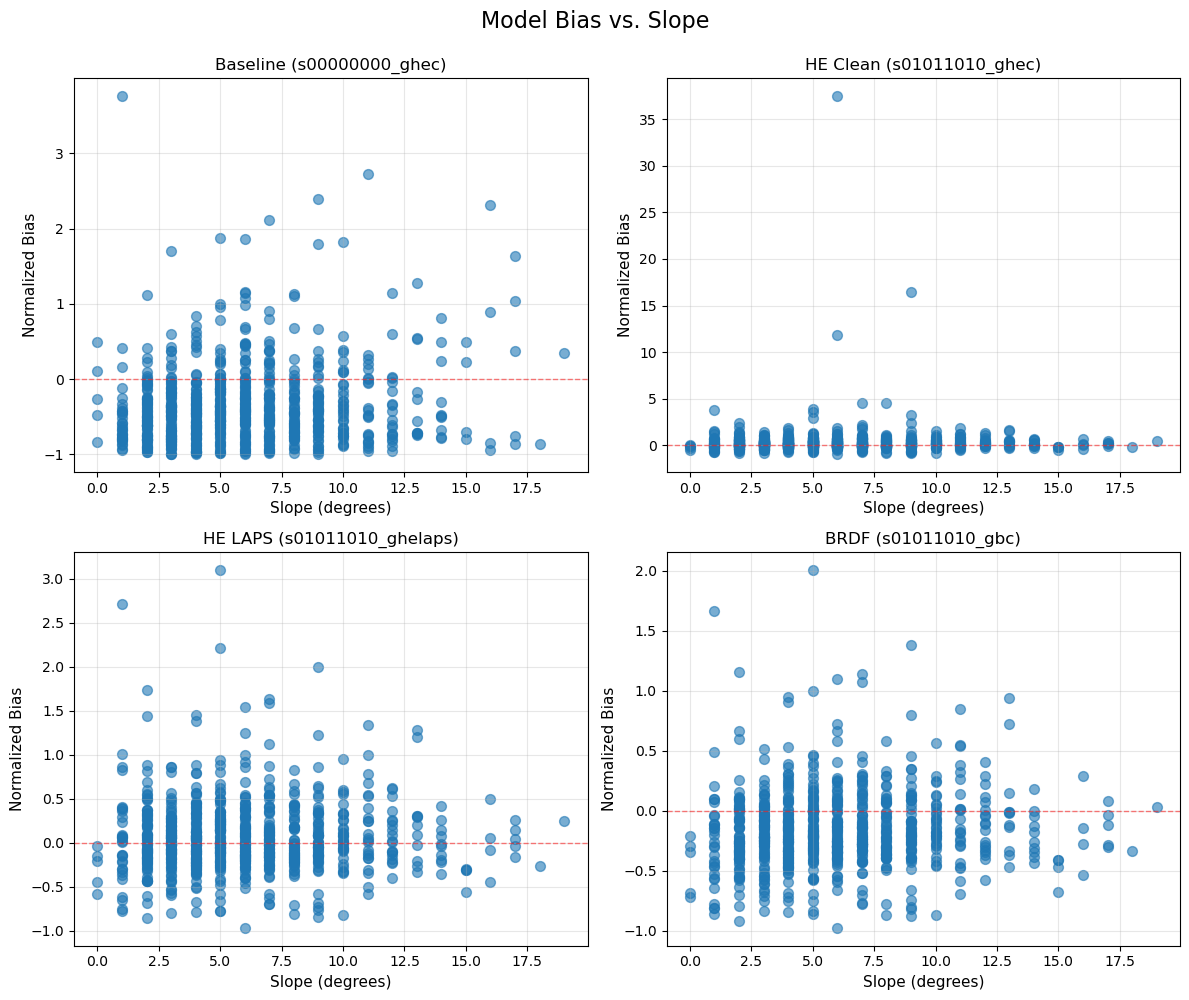

In [19]:
# Create 2x2 subplot figure for SLOPE
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Slope', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['SLOPE'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Slope (degrees)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()